In [1]:
import json

with open(".test/config.json") as json_file:
    config = json.load(json_file)  
    model_name = config['model']['name']
    model_params = config['model'].get('params', {})
    training_params = config['training']
    data_params = config['data']

with open('.test/idx_to_class.json', 'r') as f:
    idx_to_class = json.load(f)
    
num_classes = len(idx_to_class)

In [2]:
import torch
import torchvision.transforms.v2 as transforms

In [3]:
transform = transforms.Compose([
    transforms.Resize(data_params['image_size']),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=data_params['mean'], std=data_params['std']),
])

In [4]:
import src.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device='cpu'
torch.backends.nnpack.set_flags(False)

Model = getattr(models, model_name)
model = Model(num_classes, **model_params).to(device)

model.eval()
model.load_state_dict(torch.load(f".test/models/{model_name}.pt", map_location=device))
model_name

'EfficientNetV2Model'

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

In [6]:
import numpy as np
mean = np.array(data_params["mean"])
std = np.array(data_params["std"])

In [54]:
img = Image.open("/home/gjmrem/datasets/.anime/idolmaster/shinosawa_hiro/art/__shinosawa_hiro_idolmaster_drawn_by_enu_illustip__8b2c0d70056bc41051015d358b525ff3.jpg").convert("RGB")
img = transform(img)

img_disp = img.permute(1, 2, 0).cpu().numpy() * std + mean
img_disp = np.clip(img_disp, 0, 1)

-2.5465364 189.00963


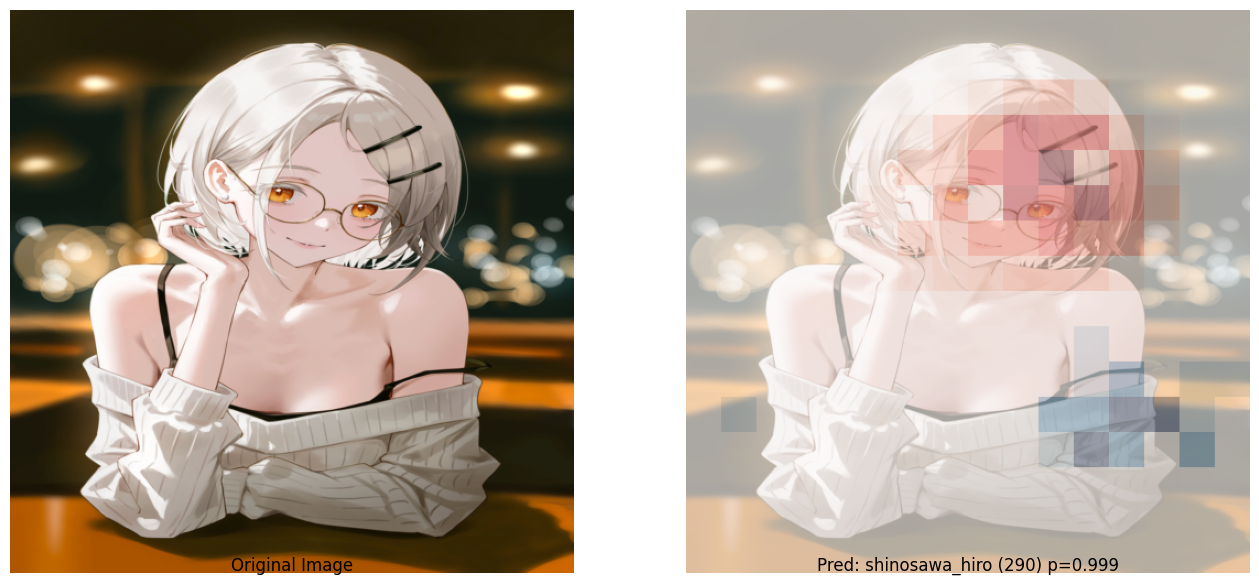

In [55]:
# 1. Load your model and set to eval mode
model.eval()

# 2. Load and preprocess your image
input_tensor = img.unsqueeze(0).to(device)

# 3. Register a hook to get the feature maps from the last conv layer
features = []
def hook_fn(module, input, output):
    features.append(output.detach().cpu().numpy())

# For ResNet, the last conv layer is usually model.resnet.layer4[-1]
# Adjust if your model structure is different
handle = model.efficientnet.features[-1][-1].register_forward_hook(hook_fn)

# 4. Forward pass
with torch.no_grad():
    output = model(input_tensor)
    pred_class = output.argmax(dim=1).item()

# 5. Get the weights of the final fc layer
params = list(model.efficientnet.classifier[-1].parameters())

weight_softmax = params[0].detach().cpu().numpy()

# 6. Compute the CAM
feature_maps = features[0][0]  # shape: [C, H, W]
cam = weight_softmax[pred_class].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam = cam.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_max = np.max(np.abs(cam))
cam_neg = np.minimum(cam, 0)
cam_pos = np.maximum(cam, 0)

print(cam.min(), cam.max())
# cam = (cam / (2*cam_max)) + (1/2)
# cam = cam - cam.min()
# cam = cam / cam.max()
cam = cam_pos / cam_max
cam_neg = - cam_neg / cam_max
      
cam = Image.fromarray((cam *255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
# cam_pos = Image.fromarray((cam_pos * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
cam_neg = Image.fromarray((cam_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

probabilities = torch.nn.functional.softmax(output, dim=1).detach().cpu().numpy()[0]
plt.figure(figsize=(16,8))

plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.title("Original Image", y=-0.01)
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam, cmap='Reds', alpha=0.5)
plt.imshow(cam_neg, cmap='Blues', alpha=0.3)
plt.title(f"Pred: {idx_to_class[str(pred_class)]} ({pred_class}) p={probabilities[pred_class]:.3}", y=-0.01)
plt.axis('off')

plt.show()

# Don't forget to remove the hook
handle.remove()

In [56]:
print(f"Top 5 predictions:")
top_indices = np.argsort(probabilities)[-5:][::-1]
for idx in top_indices:
    print(f"{idx_to_class[str(idx)]} ({idx}): {probabilities[idx]:.4f}")

Top 5 predictions:
shinosawa_hiro (290): 0.9988
yixuan_(zenless_zone_zero) (345): 0.0001
murasaki_shion (201): 0.0001
sakamata_chloe (266): 0.0001
kafuu_chino (140): 0.0000


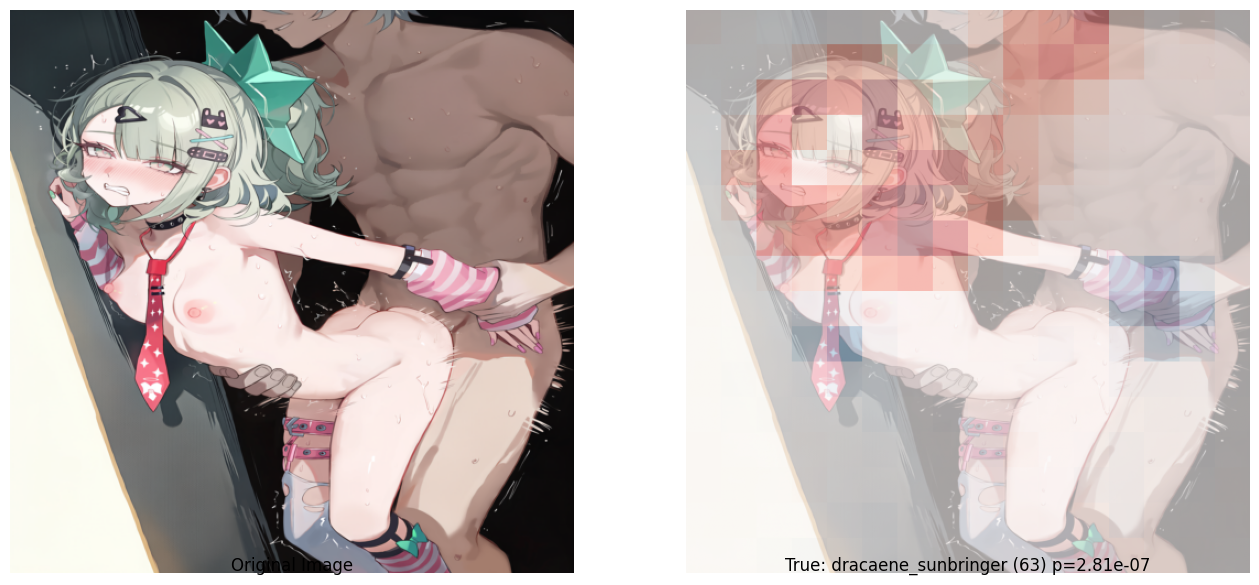

In [10]:
label = 63
cam_true = weight_softmax[label].dot(feature_maps.reshape(feature_maps.shape[0], -1))

cam_true = cam_true.reshape(feature_maps.shape[1], feature_maps.shape[2])

cam_true_max = np.max(np.abs(cam_true))
cam_true_neg = np.minimum(cam_true, 0)
cam_true = np.maximum(cam_true, 0)

cam_true = cam_true / cam_true_max
cam_true_neg = - cam_true_neg / cam_true_max

cam_true = Image.fromarray((cam_true * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_true_neg = Image.fromarray((cam_true_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))

plt.subplot(1,2,1)
# plt.imshow(img.permute(1, 2, 0))
plt.imshow(img_disp)
plt.title("Original Image", y=-0.01)
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]} ({label}) p={probabilities[label]:.3}", y=-0.01)
plt.axis('off')

plt.show()

In [11]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

In [ ]:
from pathlib import Path
folder = Path("/home/gjmrem/datasets/.toSort")
extensions = ['*.jpeg', '*.jpg', '*.png', '*.webp']
for ext in extensions:
    for file in folder.glob(ext):
        try:
            img = Image.open(file).convert("RGB")
        except OSError as e:
            print(f"Error opening image: {e}")
            continue
        
        img = transform(img)
        img = img.unsqueeze(0).to(device)
        with torch.no_grad():
            output = model(img)
            pred_class = output.argmax(dim=1).item()
            probabilities = torch.nn.functional.softmax(output, dim=1).detach().cpu().numpy()[0]
        
        if probabilities[pred_class] > 0.80:
            print(f"{file.name}:  {idx_to_class[str(pred_class)]} {probabilities[pred_class]}")
            dest_folder = file.parent/idx_to_class[str(pred_class)]          
        else:
            dest_folder = file.parent/'.other'
        
        dest_file = dest_folder/file.name
        dest_folder.mkdir(parents=True, exist_ok=True)
        file.rename(dest_file)

__ellen_joe_zenless_zone_zero_drawn_by_houkago_shounen__b6b6cad5fc9d8e0183e177a29493f91a.jpg:  ellen_joe 0.9997332692146301
__ellen_joe_zenless_zone_zero_drawn_by_greem_bang__96bb01aebe01cf1629363eacb3afce18.jpg:  ellen_joe 0.9990170001983643
__ellen_joe_zenless_zone_zero_drawn_by_skai_kun__e2e6b35ccb9191312013d7915810d7c9.jpg:  ellen_joe 0.9990744590759277
__ellen_joe_zenless_zone_zero_drawn_by_hews__2105bae7390b7d1dfe7928e4f90ba403.jpg:  ellen_joe 0.9998775720596313
__azusa_blue_archive_drawn_by_hyperlin3x__3a95cc23b5c8a2a8ad95371622db0675.jpg:  azusa_(blue_archive) 0.891285240650177
__himari_blue_archive_drawn_by_keita_kta0__6d276fc8919b43ca22734d3dddbe20f8.png:  himari_(blue_archive) 0.8843106627464294
__himari_blue_archive_drawn_by_kurokoas__f11f542385e08d55d290c9ab54ca8cfa.png:  himari_(blue_archive) 0.9934294819831848


In [ ]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

In [ ]:
from torch import nn
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from typing import Tuple, List, Dict, Optional
from pathlib import Path

class CustomImageFolder(ImageFolder):
    def __init__(self, root, class_to_idx: Dict[str, int], transform=None, target_transform=None, **kwargs):
        # Store the custom mapping
        self.custom_class_to_idx = class_to_idx
        # The custom mapping also determines the list of class names
        self.custom_classes = list(class_to_idx.keys())
        super().__init__(root, transform=transform, target_transform=target_transform,**kwargs)

    def find_classes(self, directory: str) -> Tuple[List[str], Dict[str, int]]:
        """
        Override this method to return your custom class mapping
        instead of scanning the directory.
        """
        # Return the classes and mapping you provided
        if self.custom_classes is None or self.custom_class_to_idx is None:
            # Fallback to default behavior if no custom mapping is given
            return super().find_classes(directory)
        return self.custom_classes, self.custom_class_to_idx
    
class AccuracyMetric(nn.Module):
    def __init__(self):
        super(AccuracyMetric, self).__init__()

    def forward(self, output: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        _, predicted = torch.max(output, 1)
        correct = (predicted == target).sum().item()
        return torch.tensor(correct / target.size(0), dtype=torch.float32)    

In [ ]:
class_to_idx = {cls:int(idx) for idx,cls in idx_to_class.items()}
dataset_path = Path('/home/gjmrem/datasets/.anime-test/fav')
dataset = CustomImageFolder(dataset_path, class_to_idx, transform=transform, allow_empty=True)
loader = DataLoader(dataset, batch_size=training_params['batch_size'], shuffle=False, num_workers=training_params['num_workers'], pin_memory=True, prefetch_factor=2)
criterion = nn.CrossEntropyLoss().to(device)
metric = AccuracyMetric().to(device)

In [ ]:
import torch
from typing import Optional

def validate(
    model: torch.nn.Module,
    dataloader: torch.utils.data.DataLoader,
    criterion: torch.nn.modules.loss._Loss,
    *,
    device: torch.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'),
    metric: torch.nn.Module = None,
    pbar,
    wrong_samples_file: Optional[str] = None,
    idx_to_class: Optional[dict] = idx_to_class
) -> tuple[float, float]:

    model.eval()
    epoch_loss = 0.0
    epoch_metric = 0.0

    # Open wrong samples file if requested
    f_wrong = None
    if wrong_samples_file is not None:
        f_wrong = open(wrong_samples_file, 'w')
        # Write header: filename, true label, predicted label
        f_wrong.write("filename\ttrue_label\tpredicted_label\n")

    # Check if dataset supports filename retrieval (e.g., ImageFolder)
    dataset = dataloader.dataset
    has_filenames = hasattr(dataset, 'samples') or hasattr(dataset, 'imgs')
    # For ImageFolder, samples is a list of (path, label); older versions use imgs
    if has_filenames:
        # Use samples if available, otherwise imgs
        sample_list = getattr(dataset, 'samples', getattr(dataset, 'imgs', None))
    else:
        sample_list = None

    if pbar:
        pbar.reset()

    with torch.no_grad():
        sample_idx = 0   # global index in the dataset
        for step, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
            batch_size = y.size(0)

            output = model(X)
            loss = criterion(output, y)
            epoch_loss += loss.item() * batch_size

            # Predictions
            pred = output.argmax(dim=1)

            # Write wrong samples with filenames
            if f_wrong is not None:
                pred_cpu = pred.cpu()
                y_cpu = y.cpu()
                for i in range(batch_size):
                    if pred_cpu[i] != y_cpu[i]:
                        if has_filenames and sample_list is not None:
                            # Retrieve filename using global sample index
                            filename = Path(sample_list[sample_idx + i][0])
                        else:
                            # Fallback to index if filenames not available
                            filename = f"sample_{sample_idx + i}"
                        f_wrong.write(f"{filename}\t{idx_to_class[str(y_cpu[i].item())]}\t{idx_to_class[str(pred_cpu[i].item())]}\n")

            # Update metrics and progress bar
            postfix = {f'{type(criterion).__name__}': f'{loss.item():.4f}'}
            if metric:
                batch_metric = metric(output, y)
                epoch_metric += batch_metric.item() * batch_size
                postfix.update({f'{type(metric).__name__}': f'{100.*batch_metric:.2f}%'})

            if pbar:
                pbar.update()
                pbar.set_postfix(postfix)

            sample_idx += batch_size

    if f_wrong is not None:
        f_wrong.close()

    total_samples = len(dataset)
    epoch_loss /= total_samples
    postfix = {f'avg {type(criterion).__name__}': f'{epoch_loss:.4f}'}

    if metric:
        epoch_metric /= total_samples
        postfix.update({f'avg {type(metric).__name__}': f'{100.*epoch_metric:.2f}%'})
    else:
        epoch_metric = None

    if pbar:
        pbar.set_postfix(postfix)

    return epoch_loss, epoch_metric

In [ ]:
from tqdm.autonotebook import tqdm

test_pbar = tqdm(total=len(loader), unit='batch', desc="Testing")
test_loss, test_metric = validate(model, loader, criterion, device=device,
                                  metric=metric, pbar=test_pbar,
                                  wrong_samples_file=dataset_path/"misclassified.csv")
test_pbar.close()
test_loss, test_metric

/tmp/ipykernel_9077/183743388.py:1: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm
Testing: 100%|██████████| 210/210 [02:46<00:00,  1.26batch/s, avg CrossEntropyLoss=0.3340, avg AccuracyMetric=92.48%]


(0.3340137147251294, 0.9248210023866349)

In [ ]:
break

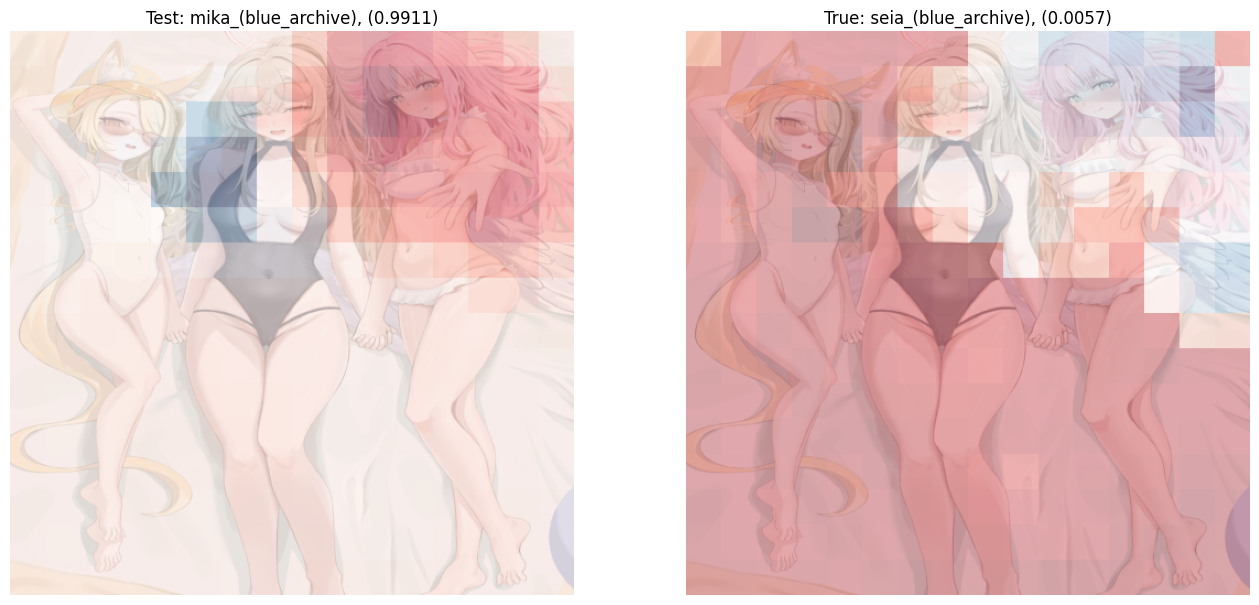

In [ ]:
test_label = 112
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
# cam_test_neg = np.minimum(cam_test, 0)
# cam_test = np.maximum(cam_test, 0)

cam_test_max = np.max(np.abs(cam_test))
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test_max
cam_test_neg = - cam_test_neg / cam_test_max

# cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
# cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}, ({probabilities[test_label]:.4f})")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}, ({probabilities[label]:.4f})")
plt.axis('off')


plt.show()

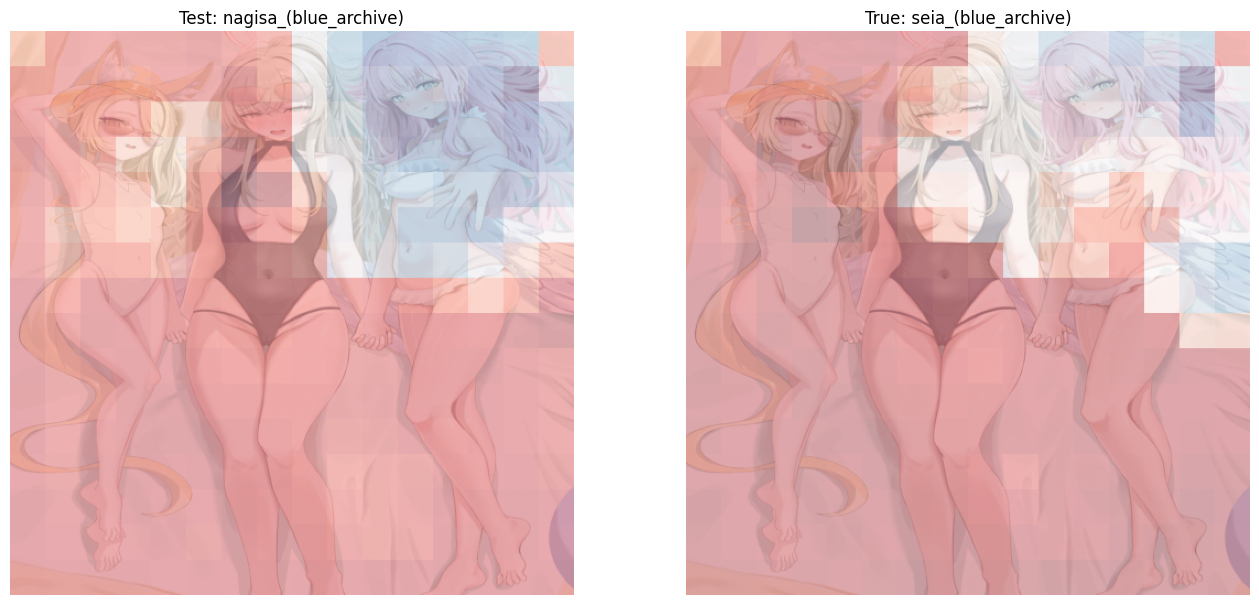

In [ ]:
test_label = 129
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
# cam_test_neg = np.minimum(cam_test, 0)
# cam_test = np.maximum(cam_test, 0)

cam_test_max = np.max(np.abs(cam_test))
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test_max
cam_test_neg = - cam_test_neg / cam_test_max

# cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
# cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

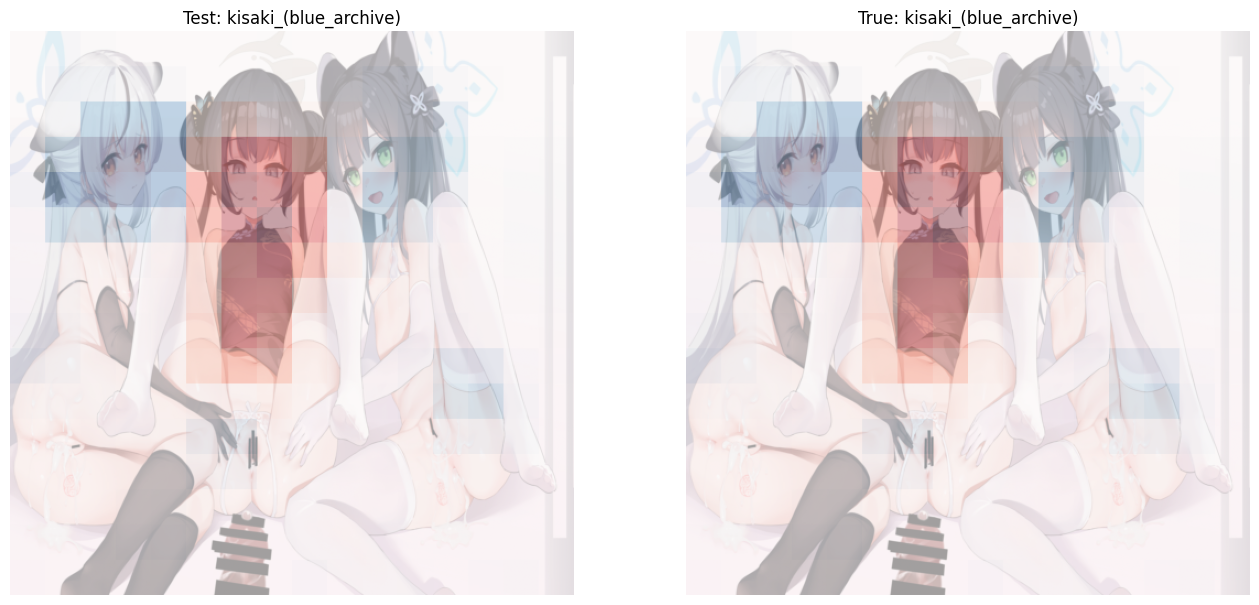

In [ ]:
test_label = 92
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
# cam_test_neg = np.minimum(cam_test, 0)
# cam_test = np.maximum(cam_test, 0)

cam_test_max = np.max(np.abs(cam_test))
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test_max
cam_test_neg = - cam_test_neg / cam_test_max

# cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
# cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

In [ ]:
break

SyntaxError: 'break' outside loop (668683560.py, line 1)

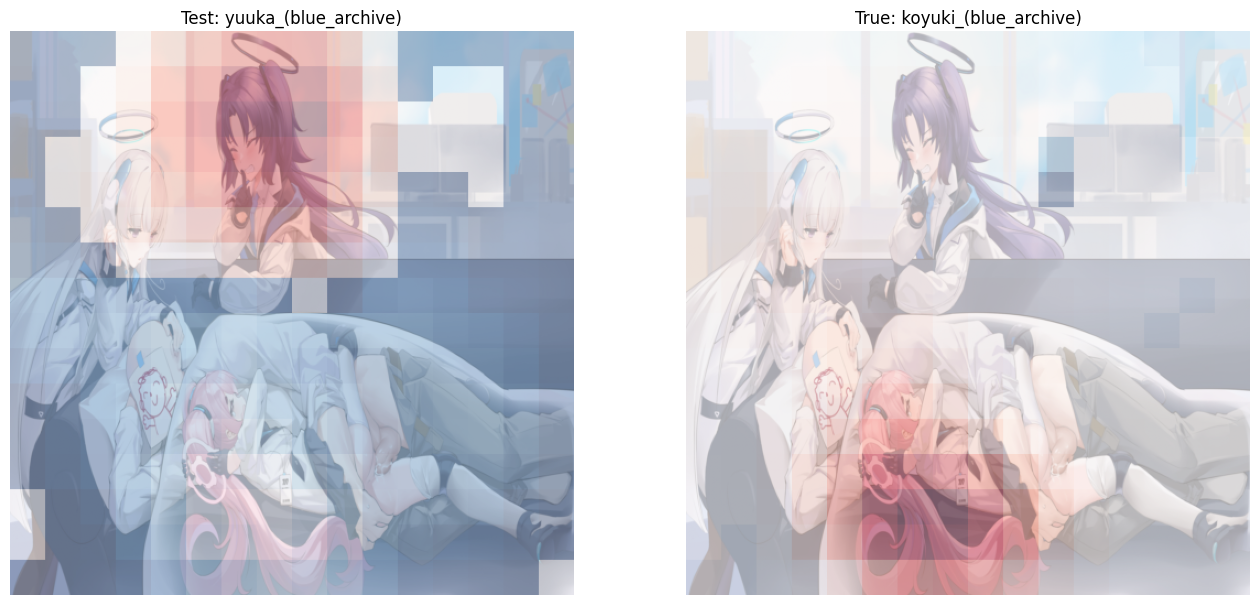

In [ ]:
test_label = 174
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

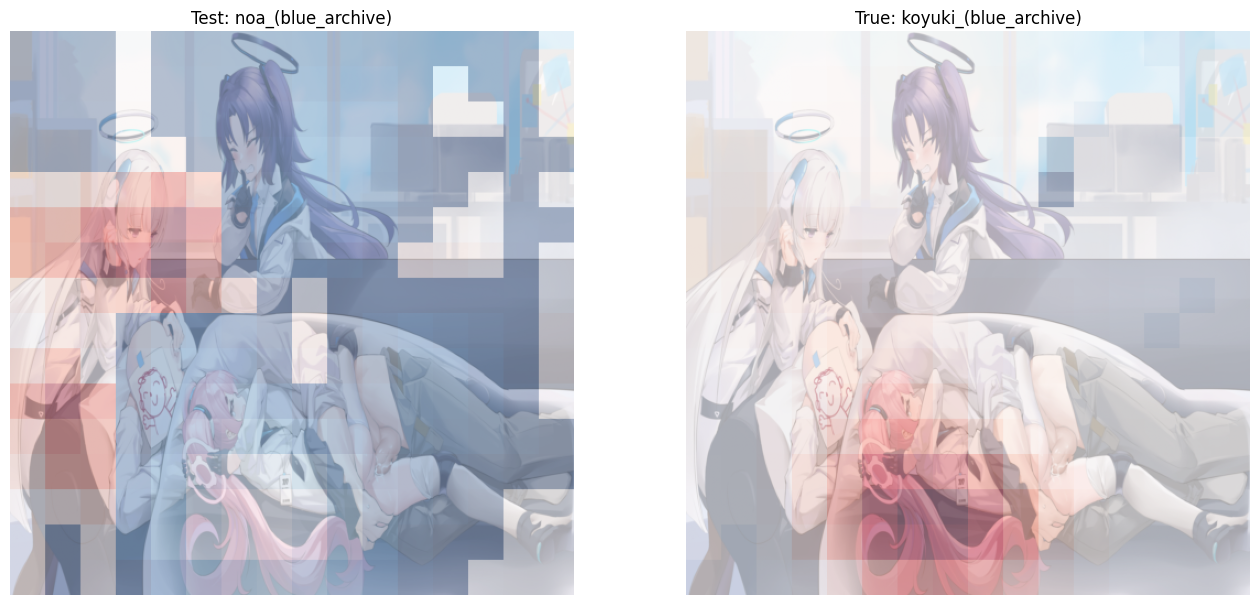

In [ ]:
test_label = 117
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
cam_test_neg = - cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BOX)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='Reds', alpha=0.5)
plt.imshow(cam_test_neg, cmap='Blues', alpha=0.3)
plt.title(f"Test: {idx_to_class[str(test_label)]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='Reds', alpha=0.5)
plt.imshow(cam_true_neg, cmap='Blues', alpha=0.3)
plt.title(f"True: {idx_to_class[str(label)]}")
plt.axis('off')


plt.show()

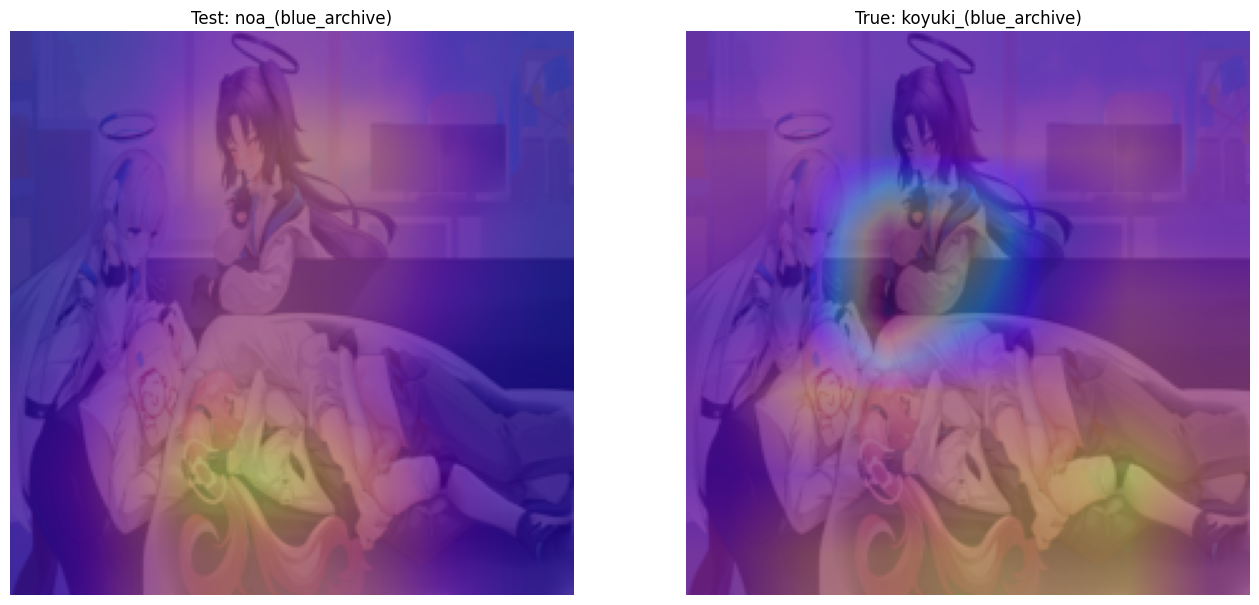

In [ ]:
test_label = 149
cam_test = weight_softmax[test_label].dot(feature_maps.reshape(feature_maps.shape[0], -1))
cam_test = cam_test.reshape(feature_maps.shape[1], feature_maps.shape[2])
# Normalize between 0-1
cam_test_neg = np.minimum(cam_test, 0)
cam_test = np.maximum(cam_test, 0)

cam_test = cam_test / cam_test.max() if cam_test.max() > 0 else cam_test
cam_test_neg = cam_test_neg / cam_test_neg.min() if cam_test_neg.min() < 0 else cam_test_neg

cam_test = Image.fromarray((cam_test * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)
cam_test_neg = Image.fromarray((cam_test_neg * 255).astype(np.uint8)).resize((img_disp.shape[1], img_disp.shape[0]), Image.BILINEAR)

plt.figure(figsize=(16,8))
plt.subplot(1,2,1)
plt.imshow(img_disp)
plt.imshow(cam_test, cmap='jet', alpha=0.5)
plt.imshow(cam_test_neg, cmap='plasma', alpha=0.5)
plt.title(f"Test: {dataset.classes[test_label]}")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(img_disp)
plt.imshow(cam_true, cmap='jet', alpha=0.5)
plt.imshow(cam_true_neg, cmap='plasma', alpha=0.5)
plt.title(f"True: {dataset.classes[label]}")
plt.axis('off')


plt.show()

In [ ]:
from tqdm.autonotebook import tqdm
# Display the confusion matrix
predictions = []
y_true = []

model.eval()
with torch.no_grad():
    for X, y in tqdm(dataloader):
        X, y = X.to(device), y.to(device)
        
        output = model(X)
        pred = output.argmax(dim=1)
        
        y_true.append(y.cpu())
        predictions.append(pred.cpu())

predictions = torch.cat(predictions)
y_true = torch.cat(y_true)

 11%|█▏        | 28/246 [05:15<37:04, 10.20s/it] /home/gjmrem/dev/projects/anime-classifier/.venv/lib/python3.10/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 4 bytes but only got 0. 
  warnings.warn(str(msg))
100%|██████████| 246/246 [56:36<00:00, 13.81s/it]


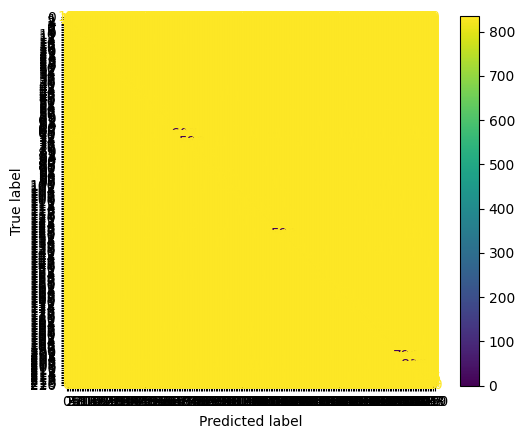

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true.numpy(), predictions.numpy())
ConfusionMatrixDisplay(cm).plot()

In [ ]:
predictions.numpy()

array([  0,   0,   0, ..., 220, 220, 220], shape=(15691,))

<Figure size 1600x1600 with 0 Axes>

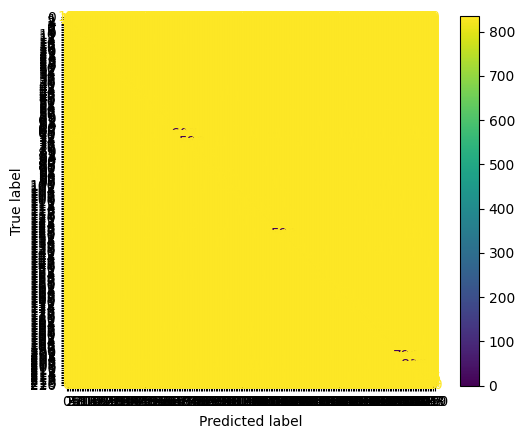

In [ ]:
plt.figure(figsize=(16,16))
ConfusionMatrixDisplay(cm).plot()

In [ ]:
import mlflow

model = mlflow.pyfunc.load_model("models:/ResNet18Model/7")

In [ ]:
from torchvision.models import swin_t
model = swin_t()
model

SwinTransformer(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (1): Permute()
      (2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (1): Sequential(
      (0): SwinTransformerBlock(
        (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (attn): ShiftedWindowAttention(
          (qkv): Linear(in_features=96, out_features=288, bias=True)
          (proj): Linear(in_features=96, out_features=96, bias=True)
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
        (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
        (mlp): MLP(
          (0): Linear(in_features=96, out_features=384, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=384, out_features=96, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (1): SwinTransformerBlock(
       